# Expectation–Maximization (EM): Latent Maize Phenotype Populations

**Lab objective:** Implement a Gaussian mixture model (GMM) from first principles using reusable **E-step** and **M-step** functions. Estimate latent population membership from observed plant height and flowering time, investigate likelihood convergence, and compare results with simulated truth.

**Prerequisites:** Normal distributions, Bayes' theorem, likelihood, arrays, and basic Python. Runs in Google Colab with NumPy, SciPy, Matplotlib, and pandas; no external datasets required.

**Learning outcomes**
1. Distinguish observed phenotypes from unobserved population labels.
2. Derive and implement posterior responsibilities (E-step).
3. Implement weighted updates for mixing proportions, means, and covariance matrices (M-step).
4. Assess likelihood convergence and initialization sensitivity.
5. Evaluate parameter recovery, label switching, and uncertainty under increasing population overlap.

> **Biological caveat:** Clusters inferred solely from phenotype do not establish genetic ancestry. In this simulation, *true* source populations are known only because we generate them.

## 1. Experimental design

Simulate (3x100)300 maize plants from three **hypothetical** source populations. Each plant has two measurements: plant height (cm) and days to flowering. Source labels are hidden during estimation.

| Parameter | Population A | Population B | Population C |
|---|---:|---:|---:|
| Plants | 100 | 100 | 100 |
| Mean height (cm) | 160 | 210 | 250 |
| Mean flowering (days) | 62 | 74 | 86 |
| Height SD (cm) | 15 | 18 | 20 |
| Flowering SD (days) | 5 | 6 | 7 |

Within each population, height and flowering time are positively correlated (ρ = 0.35).

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.special import logsumexp
from scipy.optimize import linear_sum_assignment

SEED = 42
rng = np.random.default_rng(SEED)
K = 3
N_PER_GROUP = 100
true_means = np.array([[160., 62.], [210., 74.], [250., 86.]])
true_sds = np.array([[15., 5.], [18., 6.], [20., 7.]])
true_weights = np.ones(K) / K

def covariance_from_sds(sds, rho=0.35):
    return np.outer(sds, sds) * np.array([[1., rho], [rho, 1.]])

true_covariances = np.array([covariance_from_sds(s) for s in true_sds])

def simulate_populations(rng, means, covariances, sizes):
    """Generate phenotype matrix X and source labels y (used only for validation)."""
    X_parts = [rng.multivariate_normal(mu, cov, size=int(n))
               for mu, cov, n in zip(means, covariances, sizes)]
    X = np.vstack(X_parts)
    y = np.concatenate([np.full(int(n), k) for k, n in enumerate(sizes)])
    order = rng.permutation(len(y))
    return X[order], y[order]

X, y_true = simulate_populations(rng, true_means, true_covariances,
                                  [N_PER_GROUP] * K)
print('X shape:', X.shape, '  label shape:', y_true.shape)
print('Observed variables: height (cm), flowering time (days)')

X shape: (300, 2)   label shape: (300,)
Observed variables: height (cm), flowering time (days)


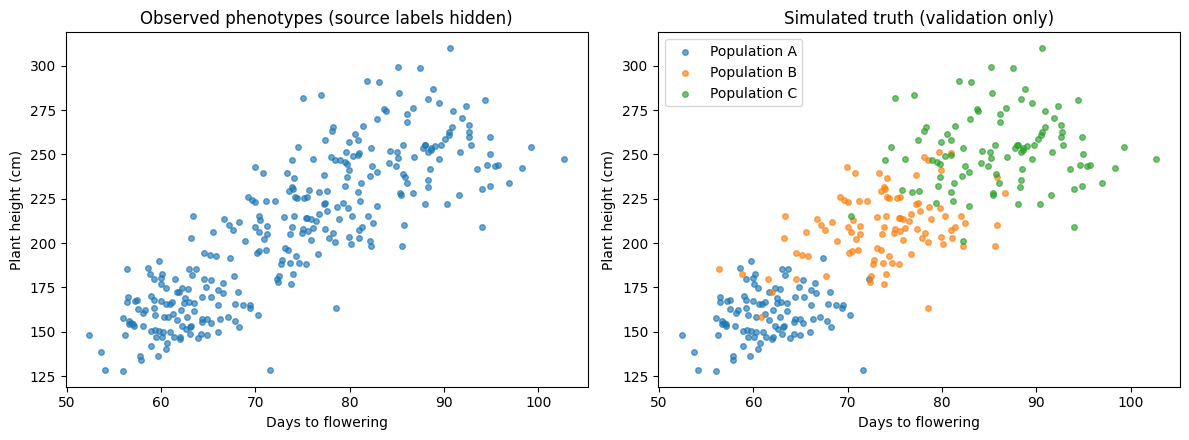

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].scatter(X[:, 1], X[:, 0], s=16, alpha=0.65)
axes[0].set(title='Observed phenotypes (source labels hidden)',
            xlabel='Days to flowering', ylabel='Plant height (cm)')
for k in range(K):
    sel = y_true == k
    axes[1].scatter(X[sel, 1], X[sel, 0], s=16, alpha=0.65,
                    label=f'Population {chr(65+k)}')
axes[1].set(title='Simulated truth (validation only)', xlabel='Days to flowering',
            ylabel='Plant height (cm)')
axes[1].legend()
plt.tight_layout()
plt.show()

## 2. Gaussian mixture likelihood

Each observation is a vector $x_i = (\text{height}_i,\text{flowering}_i)^T$. A latent source $z_i \in \{1,\dots,K\}$ selects one Gaussian component:

$$p(x_i)=\sum_{k=1}^{K}\pi_k\, N(x_i\mid\mu_k,\Sigma_k),\qquad \sum_k\pi_k=1.$$

The parameter set is $\theta=\{\pi_k,\mu_k,\Sigma_k\}_{k=1}^K$.

**E-step:** compute posterior responsibilities using the current parameters:

$$r_{ik}=P(z_i=k\mid x_i,\theta)=\frac{\pi_k N(x_i\mid\mu_k,\Sigma_k)}{\sum_{j=1}^{K}\pi_j N(x_i\mid\mu_j,\Sigma_j)}.$$

**M-step:** update parameters using fractional component memberships, $N_k=\sum_i r_{ik}$:

$$\pi_k^{new}=\frac{N_k}{N},\quad \mu_k^{new}=\frac{\sum_i r_{ik}x_i}{N_k},\quad \Sigma_k^{new}=\frac{\sum_i r_{ik}(x_i-\mu_k^{new})(x_i-\mu_k^{new})^T}{N_k}.$$

Use full covariance matrices to represent the height–flowering association. To avoid numerical underflow, compute responsibilities in **log space**. A small diagonal term regularizes covariance matrices in the implementation.

## 3. Reusable implementation: initialization, E-step, M-step

These functions accept any numeric matrix of shape `(n_observations, n_features)` and any number of components `K`. They do not depend on the maize simulation. `e_step` returns responsibilities and the observed-data log-likelihood; `m_step` returns updated parameters.

In [4]:
def initialize_gmm(X, n_components, rng, reg_covar=1e-6):
    """Select random data points as initial means; use global covariance for each group."""
    X = np.asarray(X, dtype=float)
    n, d = X.shape
    if not (1 <= n_components <= n):
        raise ValueError('n_components must be between 1 and number of observations')
    chosen = rng.choice(n, size=n_components, replace=False)
    means = X[chosen].copy()
    base_cov = np.atleast_2d(np.cov(X, rowvar=False, bias=True))
    base_cov = base_cov + reg_covar * np.eye(d)
    covariances = np.repeat(base_cov[None, :, :], n_components, axis=0)
    weights = np.full(n_components, 1.0 / n_components)
    return weights, means, covariances


def gaussian_logpdf(X, mean, covariance):
    """Stable multivariate Gaussian log-density for each row of X."""
    d = X.shape[1]
    sign, logdet = np.linalg.slogdet(covariance)
    if sign <= 0:
        raise ValueError('Covariance must be positive definite')
    delta = X - mean
    quadratic = np.einsum('ni,ni->n', delta,
                          np.linalg.solve(covariance, delta.T).T)
    return -0.5 * (d * np.log(2.0 * np.pi) + logdet + quadratic)


def e_step(X, weights, means, covariances):
    """Return responsibilities (N,K) and observed-data log-likelihood (float)."""
    X = np.asarray(X, dtype=float)
    K = len(weights)
    log_joint = np.column_stack([
        np.log(np.clip(weights[k], 1e-300, None))
        + gaussian_logpdf(X, means[k], covariances[k])
        for k in range(K)
    ])
    log_norm = logsumexp(log_joint, axis=1)
    responsibilities = np.exp(log_joint - log_norm[:, None])
    return responsibilities, float(log_norm.sum())


def m_step(X, responsibilities, reg_covar=1e-6):
    """Return updated (weights, means, covariances) for full-covariance GMM."""
    X = np.asarray(X, dtype=float)
    r = np.asarray(responsibilities, dtype=float)
    n, d = X.shape
    if r.ndim != 2 or r.shape[0] != n:
        raise ValueError('responsibilities must have shape (n_samples, K)')
    Nk = r.sum(axis=0)
    if np.any(Nk < 1e-10):
        raise ValueError('Empty component encountered; try another initialization')
    weights = Nk / n
    means = (r.T @ X) / Nk[:, None]
    K = r.shape[1]
    covariances = np.empty((K, d, d))
    for k in range(K):
        delta = X - means[k]
        covariances[k] = ((r[:, k, None] * delta).T @ delta) / Nk[k]
        covariances[k] += reg_covar * np.eye(d)
    return weights, means, covariances

### Check each step before fitting

All responsibilities should be between 0 and 1 and sum to 1 across components for every plant. The M-step should return legal mixture weights and positive-definite covariance matrices.

In [5]:
w0, mu0, cov0 = initialize_gmm(X, K, np.random.default_rng(7))
r0, ll0 = e_step(X, w0, mu0, cov0)
w1, mu1, cov1 = m_step(X, r0)
r1, ll1 = e_step(X, w1, mu1, cov1)
assert r0.shape == (len(X), K)
assert np.allclose(r0.sum(axis=1), 1.0)
assert np.all(r0 >= 0)
assert np.isclose(w1.sum(), 1.0)
assert all(np.linalg.eigvalsh(c).min() > 0 for c in cov1)
assert ll1 >= ll0 - 1e-6, 'EM update unexpectedly lowered likelihood'
print(f'Before M-step: LL = {ll0:.3f}; after M-step: LL = {ll1:.3f}')
print('E-step/M-step checks passed.')

Before M-step: LL = -2667.370; after M-step: LL = -2494.405
E-step/M-step checks passed.


## 4. Fit EM to convergence

- Record the **observed-data log-likelihood after each full update**, including iteration zero. The improvement should be nonnegative up to numerical precision. Stop when the per-observation change is small.

- Multiple starting values are recommended because EM finds local optima, not necessarily the global maximum.

In [6]:
def fit_gmm_em(X, n_components, max_iter=300, tol=1e-7,
               reg_covar=1e-6, random_state=0, n_init=5):
    """Fit a full-covariance Gaussian mixture with reusable E/M steps.

    tol: absolute change in average observed-data log-likelihood.
    Returns a dict containing parameters, responsibilities, history, iterations.
    """
    X = np.asarray(X, dtype=float)
    if X.ndim != 2 or not np.isfinite(X).all():
        raise ValueError('X must be a finite 2D matrix')
    rng = np.random.default_rng(random_state)
    best = None
    for start in range(n_init):
        weights, means, covariances = initialize_gmm(X, n_components, rng, reg_covar)
        responsibilities, loglik = e_step(X, weights, means, covariances)
        history = [loglik]
        for iteration in range(1, max_iter + 1):
            weights, means, covariances = m_step(X, responsibilities, reg_covar)
            responsibilities, loglik_new = e_step(X, weights, means, covariances)
            history.append(loglik_new)
            if loglik_new < loglik - 1e-6:
                raise RuntimeError('Likelihood decreased unexpectedly')
            if abs(loglik_new - loglik) / len(X) < tol:
                break
            loglik = loglik_new
        result = dict(weights=weights, means=means, covariances=covariances,
                      responsibilities=responsibilities,
                      log_likelihood=history[-1], history=np.array(history),
                      n_iterations=len(history) - 1, initialization=start)
        if best is None or result['log_likelihood'] > best['log_likelihood']:
            best = result
    return best

fit = fit_gmm_em(X, K, random_state=SEED, n_init=10)
print('Best initialization:', fit['initialization'])
print('Number of EM iterations:', fit['n_iterations'])
print('Final log-likelihood:', round(fit['log_likelihood'], 2))
print('Mixture weights:', np.round(fit['weights'], 3))
print('Means (height cm, flowering days):', np.round(fit['means'], 2))

Best initialization: 0
Number of EM iterations: 129
Final log-likelihood: -2455.47
Mixture weights: [0.315 0.522 0.163]
Means (height cm, flowering days): [[161.21  61.17]
 [219.98  76.47]
 [255.    90.35]]


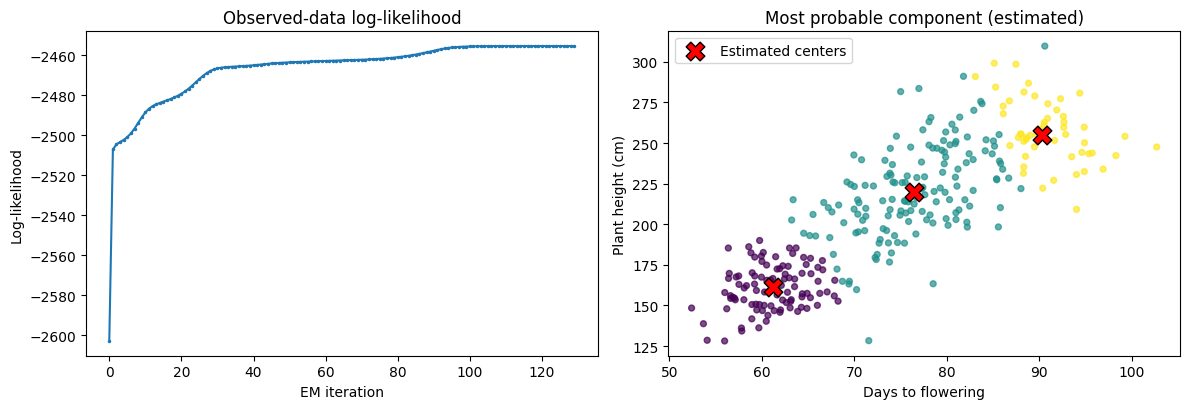

Largest negative LL increment: 2.5142244339804165e-05


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].plot(np.arange(len(fit['history'])), fit['history'], marker='.', ms=3)
axes[0].set(title='Observed-data log-likelihood', xlabel='EM iteration', ylabel='Log-likelihood')
axes[1].scatter(X[:, 1], X[:, 0], c=np.argmax(fit['responsibilities'], axis=1),
                cmap='viridis', s=18, alpha=0.7)
axes[1].scatter(fit['means'][:, 1], fit['means'][:, 0], marker='X',
                s=180, c='red', edgecolors='black', label='Estimated centers')
axes[1].set(title='Most probable component (estimated)', xlabel='Days to flowering',
            ylabel='Plant height (cm)')
axes[1].legend()
plt.tight_layout()
plt.show()
print('Largest negative LL increment:', np.min(np.diff(fit['history'])))

## 5. Validate against truth (simulation only)

Component labels can be permuted without changing the likelihood (**label switching**). Match estimated components to true labels before assessing classification accuracy. Recovery of population means is different from certainty about any one plant's membership.

In [8]:
def align_labels(y_true, responsibilities, n_components):
    """Optimal matching between predicted component labels and true labels."""
    predicted = np.argmax(responsibilities, axis=1)
    counts = np.zeros((n_components, n_components), dtype=int)
    for actual in range(n_components):
        for pred in range(n_components):
            counts[actual, pred] = np.sum((y_true == actual) & (predicted == pred))
    rows, cols = linear_sum_assignment(-counts)
    pred_to_true = {int(pred): int(actual) for actual, pred in zip(rows, cols)}
    aligned = np.array([pred_to_true[int(k)] for k in predicted])
    return aligned, pred_to_true, counts

aligned, mapping, counts = align_labels(y_true, fit['responsibilities'], K)
accuracy = np.mean(y_true == aligned)
print('Label mapping (estimated -> true):', mapping)
print('Assignment accuracy after matching:', f'{accuracy:.1%}')
rows = []
for k in range(K):
    estimated_k = next(est for est, truth in mapping.items() if truth == k)
    rows.append({'Population': chr(65 + k),
                 'True height mean': true_means[k, 0],
                 'Estimated height mean': fit['means'][estimated_k, 0],
                 'True flowering mean': true_means[k, 1],
                 'Estimated flowering mean': fit['means'][estimated_k, 1],
                 'Estimated mixture weight': fit['weights'][estimated_k]})
display(pd.DataFrame(rows).round(2))

confidence = fit['responsibilities'].max(axis=1)
print('Median maximum assignment probability:', round(float(np.median(confidence)), 3))
print('Fraction with max posterior probability < 0.8:',
      f'{np.mean(confidence < 0.8):.1%}')

Label mapping (estimated -> true): {0: 0, 1: 1, 2: 2}
Assignment accuracy after matching: 79.0%


,Population,True height mean,Estimated height mean,True flowering mean,Estimated flowering mean,Estimated mixture weight
0,A,160.0,161.21,62.0,61.17,0.32
1,B,210.0,219.98,74.0,76.47,0.52
2,C,250.0,255.00,86.0,90.35,0.16


Median maximum assignment probability: 0.969
Fraction with max posterior probability < 0.8: 21.3%



## 5. Posterior Probability Surfaces and Decision Boundaries

Evaluate the fitted Gaussian mixture model over a regular grid of plant heights and flowering times.

For every grid point $x$, calculate:

$$
P(Z=k \mid x)=
\frac{ \pi_k N(x\mid\mu_k,\Sigma_k)}
{ \sum_{j=1}^{K} \pi_j N (x\mid\mu_j,\Sigma_j)}
$$

The E-step supplies these probabilities directly.

The resulting surfaces describe the probability of membership in each latent population, not the probability density of observing a plant at that coordinate.


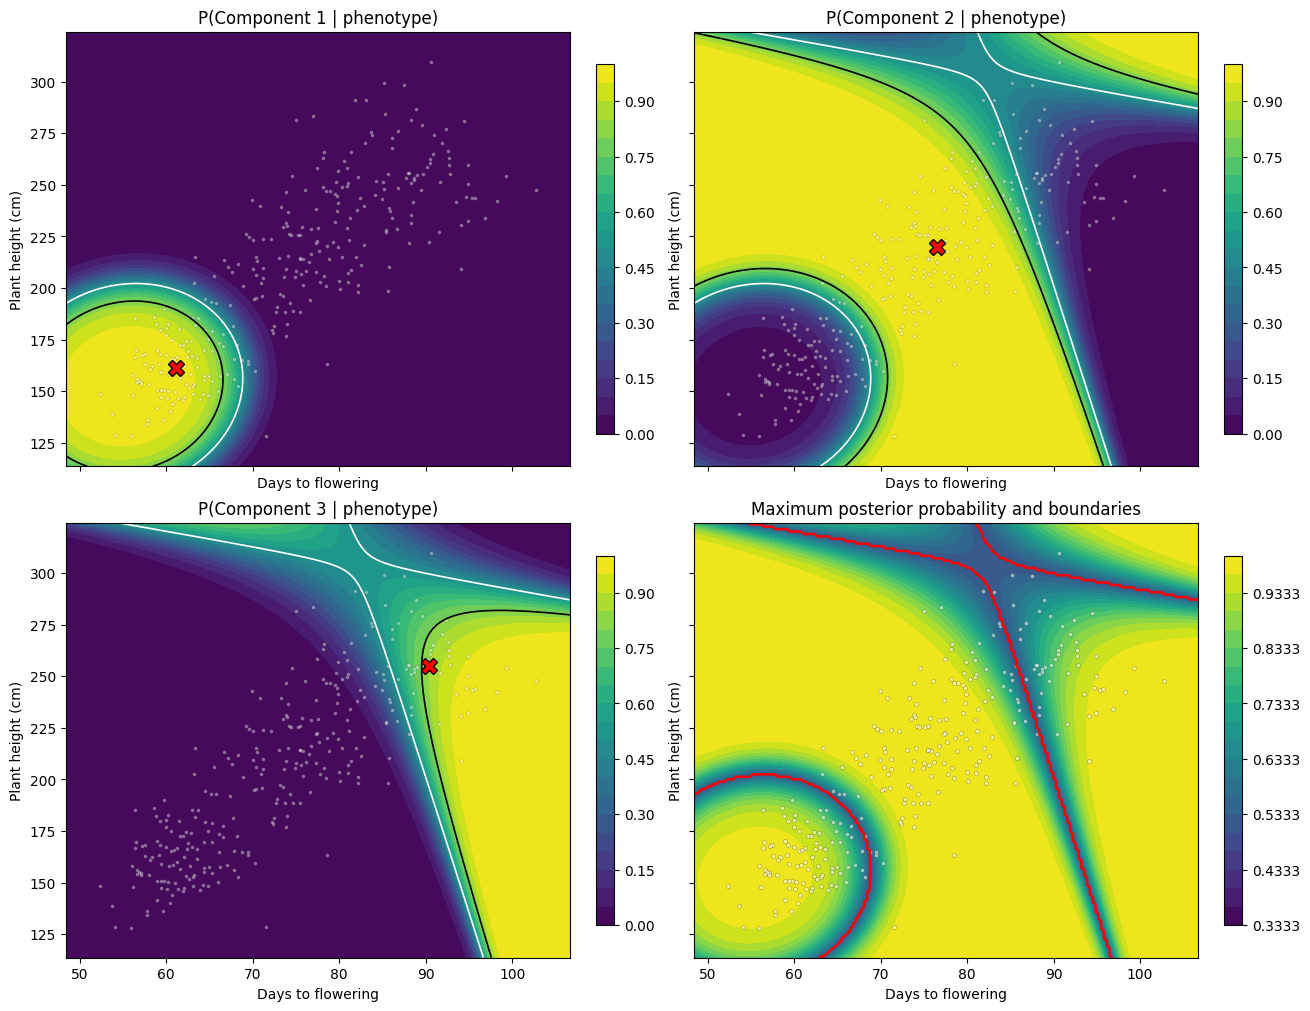

In [9]:

from matplotlib.colors import Normalize

def gmm_probability_grid(fitted, X, grid_size=180, margin=0.08):
    """Evaluate posterior probabilities over a two-feature grid."""
    X = np.asarray(X, dtype=float)
    if X.ndim != 2 or X.shape[1] != 2:
        raise ValueError("Exactly two features are required")

    mins, maxs = X.min(axis=0), X.max(axis=0)
    pad = margin * (maxs - mins)

    heights = np.linspace(
        mins[0] - pad[0], maxs[0] + pad[0], grid_size
    )
    flowering = np.linspace(
        mins[1] - pad[1], maxs[1] + pad[1], grid_size
    )

    FF, HH = np.meshgrid(flowering, heights)
    grid = np.column_stack([HH.ravel(), FF.ravel()])

    probabilities, _ = e_step(
        grid,
        fitted["weights"],
        fitted["means"],
        fitted["covariances"]
    )

    surfaces = probabilities.reshape(grid_size, grid_size, -1)
    return FF, HH, surfaces


def plot_gmm_probability_surfaces(X, fitted, grid_size=180):
    """Plot component membership surfaces and decision boundaries."""
    FF, HH, surfaces = gmm_probability_grid(
        fitted, X, grid_size=grid_size
    )

    if surfaces.shape[-1] != 3:
        raise ValueError("This visualization expects 3 components")

    fig, axes = plt.subplots(
        2, 2, figsize=(13, 10),
        sharex=True, sharey=True,
        constrained_layout=True
    )
    axes = axes.ravel()

    for k in range(3):
        ax = axes[k]

        im = ax.contourf(
            FF, HH, surfaces[:, :, k],
            levels=np.linspace(0, 1, 21),
            cmap="viridis",
            norm=Normalize(0, 1)
        )

        ax.contour(
            FF, HH, surfaces[:, :, k],
            levels=[0.5, 0.8],
            colors=["white", "black"],
            linewidths=1.2
        )

        ax.scatter(
            X[:, 1], X[:, 0],
            s=7, c="white", alpha=0.4,
            edgecolors="black", linewidths=0.2
        )

        ax.plot(
            fitted["means"][k, 1],
            fitted["means"][k, 0],
            "X", color="red", markersize=11,
            markeredgecolor="black"
        )

        ax.set_title(f"P(Component {k+1} | phenotype)")
        fig.colorbar(im, ax=ax, shrink=0.85)

    ax = axes[3]

    winner = np.argmax(surfaces, axis=2)
    confidence = np.max(surfaces, axis=2)

    im = ax.contourf(
        FF, HH, confidence,
        levels=np.linspace(1/3, 1, 21),
        cmap="viridis"
    )

    ax.contour(
        FF, HH, winner,
        levels=[0.5, 1.5],
        colors="red", linewidths=1.8
    )

    ax.scatter(
        X[:, 1], X[:, 0],
        s=9, c="white", alpha=0.5,
        edgecolors="black", linewidths=0.25
    )

    ax.set_title("Maximum posterior probability and boundaries")
    fig.colorbar(im, ax=ax, shrink=0.85)

    for ax in axes:
        ax.set_xlabel("Days to flowering")
        ax.set_ylabel("Plant height (cm)")

    plt.show()
    return FF, HH, surfaces


# Run visualization using the existing EM fit.
FF, HH, posterior_surfaces = plot_gmm_probability_surfaces(X, fit)

# Validate probability normalization.
assert np.allclose(posterior_surfaces.sum(axis=2), 1.0)

## Interpretation of the EM Posterior Probability Surfaces

The figure illustrates how the Expectation-Maximization (EM) algorithm classifies maize plants with missing population labels (with distictive phenotypic profiles) into three latent phenotypic populations using two observed traits: days to flowering (x-axis) and plant height (y-axis).

The model estimates three Gaussian components, each characterized by its own mean, covariance matrix, and mixture proportion.

- The figure demonstrates how EM transforms estimates of latent population distributions into probabilistic assignments to classes.

- The most important insight is that a region of high classification confidence is not necessarily a region of high observation probability.

- This procedure also serves as a method for identification of the decision boundary, which will be described below.

### 1. Individual population probability surfaces

- yellow = high posterior membership probability;
- purple = low probability.
- Red X = estimated component mean.

| Panel                     | Interpretation                                                                                                                                                                                         |
| ------------------------- | ------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------ |
| Component 1 — Upper left  | Concentrated around approximately 61 days to flowering and 160 cm plant height. This is the earliest-flowering and shortest population, with a relatively compact probability region.                  |
| Component 2 — Upper right | Centered near 77 days and 220 cm. Its probability surface occupies a broad, curved region between the other populations and extends into areas with unusual combinations of height and flowering time. |
| Component 3 — Lower left  | Centered near 91 days and 255 cm. This late-flowering, tall population has a strong membership region toward the right of the plot.                                                                    |

The three probability surfaces satisfy:

\\[ P(Z=1\mid X)+P(Z=2\mid X)+P(Z=3\mid X)=1 \\]

at every coordinate.

### 2. Decision boundaries and classification confidence

The bottom-right panel displays the maximum posterior membership probability:

\\[ C(x)=\max_k P(Z=k\mid x) \\]

The red lines represent boundaries where two components exchange dominance.

- Yellow regions: One component dominates, giving high classification confidence.
- Blue/green regions: Multiple components have comparable probabilities, indicating assignment uncertainty.
- Red boundaries: The most probable component changes from one population to another.

Importantly, the boundaries are nonlinear. This arises because the components have different estimated covariance matrices, and therefore different shapes, orientations, and dispersions in phenotype space.

### 3. An important observation: the probability regions are not elliptical

Although each component is modeled with a multivariate Gaussian distribution, the posterior probability surfaces are not necessarily elliptical.

This is because the plotted quantity is

\\[ P(Z=k\mid X=x) \\]

rather than

\\[ p(X=x\mid Z=k) \\]

The first represents relative membership probability, whereas the second represents the phenotypic probability density within a component.

Consequently, Component 2 can have a very high posterior probability far from its estimated mean. This occurs where the other two Gaussian components have even lower densities.

The broad yellow regions outside the observed data should therefore not be interpreted as regions where maize plants are likely to occur.

### 4. What does this tell us about EM?

The figure demonstrates three important properties.

First, EM produces probabilistic assignments rather than requiring hard classification. Each plant has three membership probabilities, allowing uncertainty to be represented explicitly.

Second, classification uncertainty depends on the joint phenotype distribution. Plants are assigned using combinations of flowering time and height, with covariance affecting membership.

Third, posterior confidence is not the same as model validity. Even a high posterior probability does not guarantee the corresponding component represents a biologically distinct population.

### 5. Gaussian Probability Density Surface Vizualition

Gaussian probability density surfaces can also be vizualized from the data:

\\[ p(X\mid Z=k)=\mathcal N(X\mid\mu_k,\Sigma_k) \\]

Note that the probability densities are distinct from likelihood surfaces.


| Gaussian density surface                                    | Posterior probability surface                                           |
| ----------------------------------------------------------- | ----------------------------------------------------------------------- |
| Where are plants from population \\(k\\) expected to occur? | Given a plant phenotype, which population is its most probable origin?  |
| Describes phenotypic distribution                           | Describes membership probability                                        |
| Reflects component mean and covariance                      | Also depends on competing components and mixture proportions            |
| High density indicates typical phenotypes                   | High posterior probability indicates relative classification confidence |


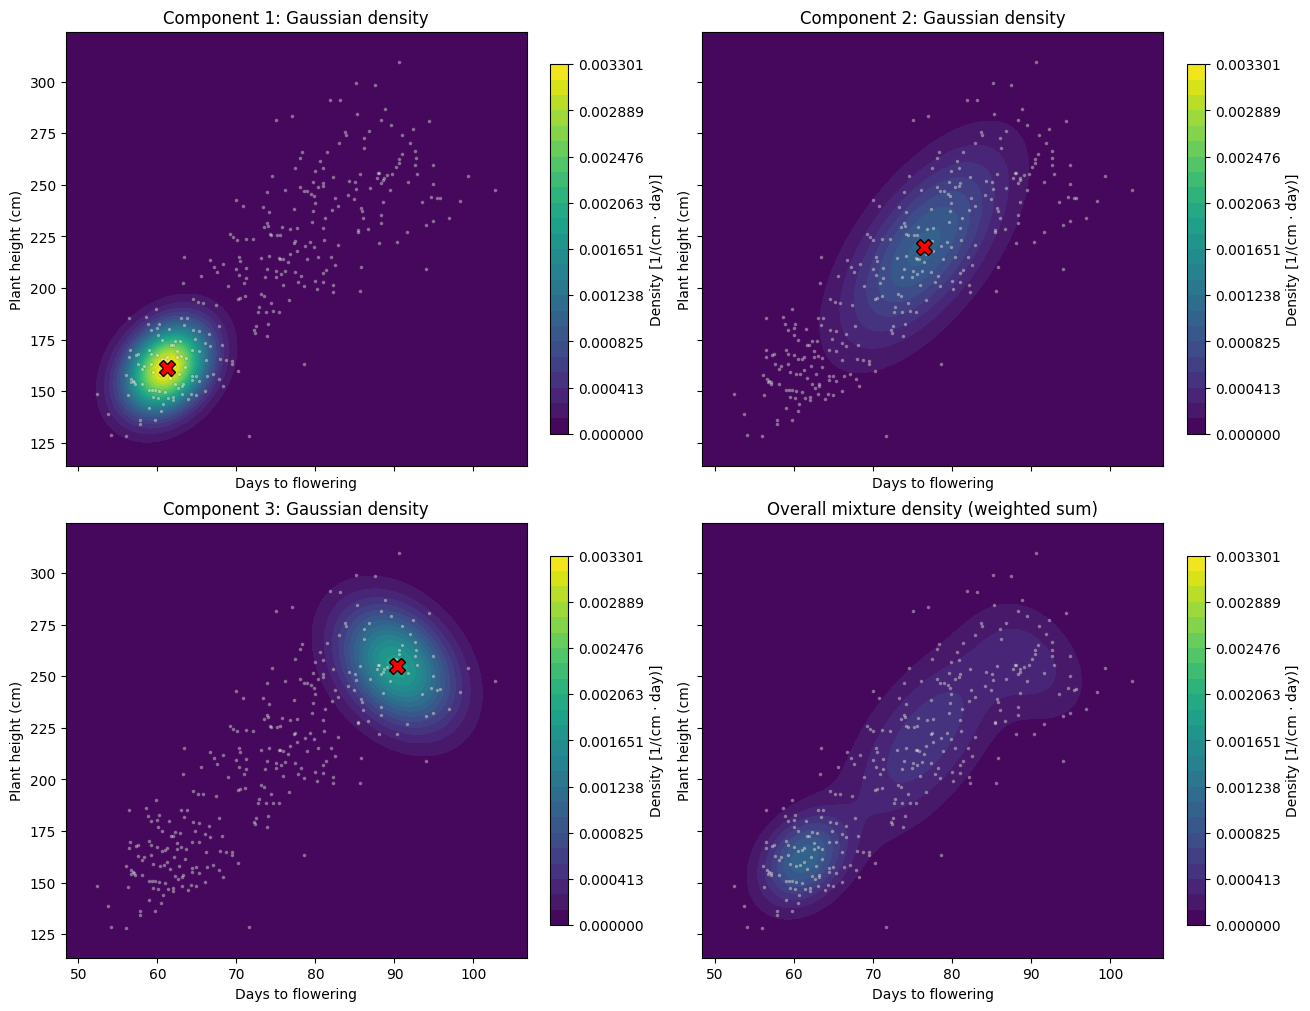

Density-surface shapes: (180, 180, 3) (180, 180)


In [12]:
from scipy.special import logsumexp


def gmm_density_grid(fitted, X, grid_size=180, margin=0.08):
    """Evaluate Gaussian component densities and their weighted mixture on a 2D grid.

    Feature order: X[:, 0] = height (cm); X[:, 1] = flowering time (days).
    Returns: FF, HH, component_densities, mixture_density.
    """
    X = np.asarray(X, dtype=float)
    if X.ndim != 2 or X.shape[1] != 2:
        raise ValueError('Density surfaces require exactly two features')
    mins, maxs = X.min(axis=0), X.max(axis=0)
    pad = margin * (maxs - mins)
    heights = np.linspace(mins[0] - pad[0], maxs[0] + pad[0], grid_size)
    flowering = np.linspace(mins[1] - pad[1], maxs[1] + pad[1], grid_size)
    FF, HH = np.meshgrid(flowering, heights)
    points = np.column_stack([HH.ravel(), FF.ravel()])

    # Use the SAME gaussian_logpdf() function as the existing E-step.
    log_component = np.column_stack([
        gaussian_logpdf(points, fitted['means'][k], fitted['covariances'][k])
        for k in range(len(fitted['weights']))
    ])
    component = np.exp(log_component).reshape(*HH.shape, -1)
    log_mix = logsumexp(log_component + np.log(fitted['weights'])[None, :], axis=1)
    mixture = np.exp(log_mix).reshape(HH.shape)
    return FF, HH, component, mixture


def plot_gmm_density_surfaces(X, fitted, grid_size=180):
    """Show three component densities and overall Gaussian mixture density."""
    FF, HH, densities, mixture = gmm_density_grid(fitted, X, grid_size)
    if densities.shape[-1] != 3:
        raise ValueError('This four-panel teaching plot expects three components')

    from matplotlib.colors import Normalize
    common_max = max(float(densities.max()), float(mixture.max()))
    norm = Normalize(vmin=0, vmax=common_max)
    levels = np.linspace(0, common_max, 25)
    fig, axes = plt.subplots(2, 2, figsize=(13, 10), sharex=True, sharey=True,
                             constrained_layout=True)
    for k, ax in enumerate(axes.ravel()):
        values = densities[:, :, k] if k < 3 else mixture
        im = ax.contourf(FF, HH, values, levels=levels, norm=norm, cmap='viridis')
        ax.scatter(X[:, 1], X[:, 0], s=7, c='white', alpha=0.4,
                   edgecolors='black', linewidths=0.2)
        if k < 3:
            ax.plot(fitted['means'][k, 1], fitted['means'][k, 0], 'X',
                    color='red', markersize=11, markeredgecolor='black')
            ax.set_title(f'Component {k+1}: Gaussian density')
        else:
            ax.set_title('Overall mixture density (weighted sum)')
        ax.set_xlabel('Days to flowering')
        ax.set_ylabel('Plant height (cm)')
        fig.colorbar(im, ax=ax, shrink=0.85, label='Density [1/(cm · day)]')
    plt.show()
    return FF, HH, densities, mixture

FF_d, HH_d, component_densities, mixture_density = plot_gmm_density_surfaces(X, fit)
assert np.allclose(mixture_density, component_densities @ fit['weights'])
print('Density-surface shapes:', component_densities.shape, mixture_density.shape)

## **Figure Interpretations:**

The decision boundaries in the bottom-right panel of the first Figure form three nonlinear, curved boundaries separating the regions dominated by the three Gaussian mixture components.

### Boundary between Components 1 and 2: Rounded, dome-shaped

- Forms a curved arc around Component 1, centered approximately at 61 days to flowering and 160 cm plant height.
- Resembles a semicircular or elliptical boundary, enclosing the region where Component 1 has the highest posterior probability.
- The boundary is relatively tight, suggesting Component 1 has a more concentrated phenotypic distribution than Component 2.

### Boundary between Components 2 and 3: Sloping, nearly vertical curve

- Runs from approximately 87 days and 315 cm toward 98 days and 115 cm.
- Has a pronounced curvature rather than forming a straight line.
- Separates the broad region dominated by Component 2 from the late-flowering, tall phenotype region dominated by Component 3.
- Its shape reflects differences in the covariance structures of the two components.

### 3. Upper boundary between Components 2 and 3: Broad, shallow arc

- Extends across the upper portion of the plot, from approximately 55 days and 325 cm toward the central junction near 87 days and 315 cm.
- Curves gently downward before joining the steeper boundary.
- Creates a narrow region at the top where Component 3 becomes more probable than Component 2, despite flowering times that would ordinarily be associated with earlier populations.

### Why are the boundaries curved?

For two Gaussian components, the decision boundary occurs where their weighted densities are equal:

\\[ \pi_i N(x\mid\mu_i,\Sigma_i) = \pi_j N(x\mid\mu_j,\Sigma_j) \\]

Taking logarithms produces a quadratic equation in the two phenotypic variables:

\\[ x^\top A x+b^\top x+c=0 \\]

This means Gaussian mixture decision boundaries can be elliptical, hyperbolic, parabolic, or approximately linear, depending on the estimated covariance matrices.

- Equal covariance matrices produce linear boundaries.
- Different covariance matrices generally produce quadratic boundaries.
- Correlation between plant height and flowering time can rotate and distort these boundaries.

The boundaries between Components 2 and 3 produce an unusual branching configuration near the top of the plot. It reflects the different covariance structures of the components rather than a simple threshold in flowering time or plant height.

The shallow upper arc and steep right-hand curve should not necessarily be interpreted as one continuous pairwise boundary: their meeting region may involve all three components.

Overall: The decision regions are not simple rectangular partitions or straight thresholds. They are curved, covariance-dependent regions, demonstrating that EM-based Gaussian mixture classification depends on the joint distribution of flowering time and plant height rather than either trait independently.

## Gradable Segment:
## Does more overlap between group characteristics make inference harder?

If we increase the **within-population standard deviations** while keeping the population means unchanged, we would be creating more overlap between groups.

 *Greater overlap generally reduces assignment confidence and may reduce classification accuracy*, even when EM successfully maximizes likelihood. Monte Carlo variation and local optima can affect any single run.

,SD multiplier,Matched accuracy,Median max posterior,Log-likelihood
0,0.65,0.943,1.000,-2272.819
1,1.00,0.860,0.999,-2473.065
2,1.50,0.770,0.976,-2647.326
3,2.00,0.697,0.944,-2772.990


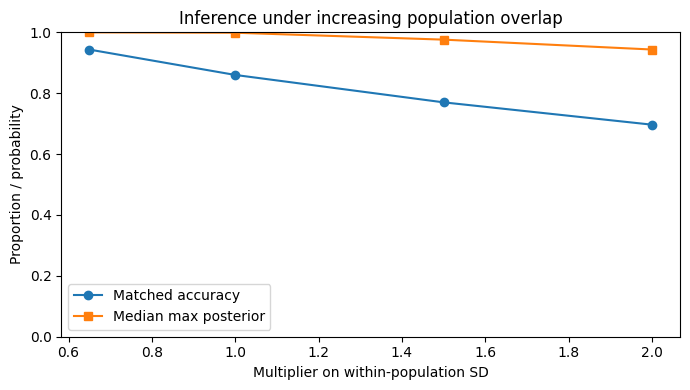

In [10]:
overlap_results = []
for factor in [0.65, 1.0, 1.5, 2.0]:
    cov_scaled = true_covariances * factor**2
    Xt, yt = simulate_populations(np.random.default_rng(100), true_means,
                                   cov_scaled, [N_PER_GROUP] * K)
    fitted = fit_gmm_em(Xt, K, n_init=8, random_state=42)
    assigned, _, _ = align_labels(yt, fitted['responsibilities'], K)
    overlap_results.append({'SD multiplier': factor,
                            'Matched accuracy': np.mean(assigned == yt),
                            'Median max posterior': np.median(fitted['responsibilities'].max(axis=1)),
                            'Log-likelihood': fitted['log_likelihood']})
results = pd.DataFrame(overlap_results)
display(results.round(3))
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(results['SD multiplier'], results['Matched accuracy'], 'o-', label='Matched accuracy')
ax.plot(results['SD multiplier'], results['Median max posterior'], 's-', label='Median max posterior')
ax.set(xlabel='Multiplier on within-population SD', ylabel='Proportion / probability',
       ylim=(0, 1), title='Inference under increasing population overlap')
ax.legend()
plt.tight_layout()
plt.show()

# **Making predictions for New Samples with the Fitted Model**
The fitted Gaussian Mixture Model (GMM) is capable of making predictions for new samples.

The key is to separate model fitting from prediction.

During training, EM estimates the parameters of the three latent maize populations:

$$
  {\hat\theta} =
  \{
  {\hat\pi_k},{\hat\mu_k},{\hat\Sigma_k}
  \}_{k=1}^{3}
$$

For a new maize plant, you measure its height and flowering time and use those previously estimated parameters to calculate its population membership probabilities.

You do not rerun EM for every new plant.

## 1. What can the model predict?

For a new plant with phenotype vector

$$
x_{\mathrm{new}}=
\begin{bmatrix}
\text{Plant height}\\\
\text{Days to flowering}
\end{bmatrix}
$$

the model can produce:

| Prediction                | Interpretation                                                                      |
| ------------------------- | ----------------------------------------------------------------------------------- |
| Population membership     | Most probable latent population                                                     |
| Posterior probabilities   | Probability assigned to each of the three components                                |
| Classification confidence | Highest posterior membership probability                                            |
| Phenotype likelihood      | How well the phenotype fits the modeled distribution, expressed as a density        |
| Novelty indicator         | Whether the sample lies outside a chosen reference region of the fitted populations |

The last two are particularly important. A new sample might have 99% posterior membership probability for Population 2 even though its phenotype is extremely unusual under all three populations.

Therefore, we should evaluate both relative population membership and absolute compatibility with the fitted distributions.

## 2. Add a reusable prediction function

This function uses the fitted parameters and the existing `e_step()` implementation. It also computes how unusual each new sample is relative to its assigned component.

The function returns a predicted population, membership probabilities, and whether each plant falls within the chosen 95% Gaussian reference ellipse of its assigned component.

The ellipse is a model-based reference region, not a guarantee of correct classification.

## 3. Visualize new predictions on the existing decision surface

This uses the previously fitted EM parameters, so the decision boundaries remain fixed when new samples are introduced.

## 4. Evaluate predictive performance

For your simulated maize experiment, the true population identities are known. That allows an external validation exercise.

I recommend fitting EM on a training set, then assigning held-out plants without updating any mixture parameters. Compare those predictions against their simulated population origins after aligning component labels.

For real unlabeled samples, you cannot directly calculate classification accuracy. Instead, assess held-out log density, stability of assignments, and changes in the phenotype distributions.

One important limitation: because the model is unsupervised, predicted population labels mean estimated Gaussian components. They do not establish genetic ancestry unless independently validated.

## 5. Predictive versus adaptive models

There are two distinct directions you could take:

| Fixed predictive model                     | Adaptive model                                |
| ------------------------------------------ | --------------------------------------------- |
| Estimate EM parameters once                | Update parameters as observations accumulate  |
| Classify new plants using fixed boundaries | Allow boundaries to change                    |
| Good for reproducible validation           | Good for studying temporal population changes |
| No retraining for individual predictions   | Requires controlled model updates             |

For the teaching notebook, I recommend the fixed predictive model first. It creates a clear distinction between fitting a model, applying it to new samples, and evaluating whether its inferred population structure generalizes.

The natural next extension would be to classify a fourth simulated population absent from the training data and examine why high posterior confidence alone fails to identify genuinely novel phenotypes.


In [13]:
# Reusable Prediction Function

import numpy as np
import pandas as pd
from scipy.stats import chi2

def predict_gmm(X_new, fitted, coverage=0.95):
    """
    Predict latent population membership for new maize plants.

    X_new columns:
        0: Plant height (cm)
        1: Days to flowering

    Uses existing e_step(), without refitting EM.
    """
    X_new = np.atleast_2d(np.asarray(X_new, dtype=float))

    if X_new.shape[1] != fitted["means"].shape[1]:
        raise ValueError("Incorrect number of phenotype features")

    if not np.isfinite(X_new).all():
        raise ValueError("New observations must be finite")

    probabilities, _ = e_step(
        X_new,
        fitted["weights"],
        fitted["means"],
        fitted["covariances"]
    )

    assigned = np.argmax(probabilities, axis=1)
    confidence = probabilities.max(axis=1)

    # Squared Mahalanobis distance to the assigned component
    distances = np.empty(len(X_new))

    for i, k in enumerate(assigned):
        delta = X_new[i] - fitted["means"][k]
        distances[i] = delta @ np.linalg.solve(
            fitted["covariances"][k], delta
        )

    # Gaussian reference-region threshold
    threshold = chi2.ppf(coverage, df=X_new.shape[1])

    return pd.DataFrame({
        "Plant_height_cm": X_new[:, 0],
        "Flowering_days": X_new[:, 1],
        "Predicted_population": assigned + 1,
        "Confidence": confidence,
        **{
            f"P_population_{k+1}": probabilities[:, k]
            for k in range(probabilities.shape[1])
        },
        "Mahalanobis_D2": distances,
        "Inside_reference_ellipse": distances <= threshold
    })


# Three previously unseen plants
X_new = np.array([
    [165, 63],
    [218, 76],
    [260, 90]
])

predictions = predict_gmm(X_new, fit)
display(predictions.round(3))

,Plant_height_cm,Flowering_days,Predicted_population,Confidence,P_population_1,P_population_2,P_population_3,Mahalanobis_D2,Inside_reference_ellipse
0,165.0,63.0,1,0.945,0.945,0.055,0.000,0.285,True
1,218.0,76.0,2,1.000,0.000,1.000,0.000,0.006,True
2,260.0,90.0,3,0.818,0.000,0.182,0.818,0.069,True


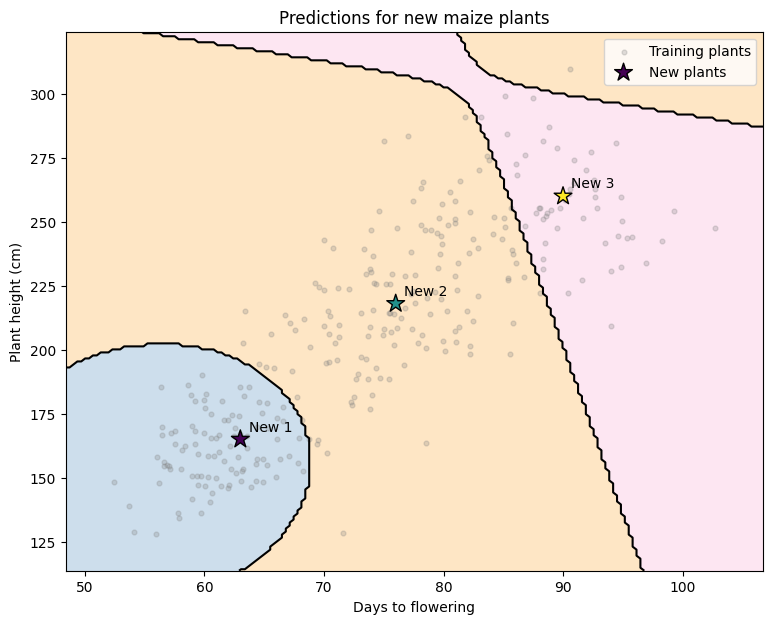

In [14]:
## Decision Surface Visualization

FF, HH, surfaces = gmm_probability_grid(fit, X)

predicted_labels = predictions["Predicted_population"].to_numpy()

fig, ax = plt.subplots(figsize=(9, 7))

ax.contourf(
    FF, HH,
    np.argmax(surfaces, axis=2),
    levels=[-0.5, 0.5, 1.5, 2.5],
    cmap="Pastel1",
    alpha=0.65
)

ax.contour(
    FF, HH,
    np.argmax(surfaces, axis=2),
    levels=[0.5, 1.5],
    colors="black",
    linewidths=1.5
)

ax.scatter(
    X[:, 1], X[:, 0],
    s=12, c="gray", alpha=0.25,
    label="Training plants"
)

ax.scatter(
    X_new[:, 1], X_new[:, 0],
    c=predicted_labels,
    cmap="viridis",
    vmin=1, vmax=3,
    s=180, marker="*",
    edgecolors="black",
    linewidths=1,
    label="New plants"
)

for i, (h, f) in enumerate(X_new):
    ax.annotate(
        f"New {i+1}",
        (f, h),
        xytext=(6, 6),
        textcoords="offset points"
    )

ax.set_xlabel("Days to flowering")
ax.set_ylabel("Plant height (cm)")
ax.set_title("Predictions for new maize plants")
ax.legend()

plt.show()


## 7. Student exercises and discussion

1. **Posterior membership:** Choose one observation and inspect its complete responsibility vector. Explain why the entries sum to one and why no categorical assignment is necessary during EM.
2. **Known vs unknown parameters:** If the population means and covariances were known, what would the E-step estimate? Which M-step operations could be omitted?
3. **Covariance:** Modify `covariance_from_sds` to use `rho=0`. Re-simulate and re-fit. How does the geometry of the phenotype distributions change?
4. **Population overlap:** Use the results above to distinguish *classification uncertainty* from *parameter estimation error*.
5. **Initialization:** Run with `n_init=1` using several random seeds and compare final likelihoods. Does convergence always lead to the same estimates?
6. **Number of components:** Fit `K=2`, `K=3`, and `K=4`. Compare log-likelihood, parameter interpretability, and whether additional components necessarily represent biological populations.
7. **Identifiability:** Explain how label switching differs from the failure to identify a model's parameters from its observed distribution.
8. **Biological inference:** What additional data (genotypes, pedigrees, environments, replication) would be needed before claiming the recovered components correspond to genetic populations?

### Optional exercise: BIC

For a full-covariance Gaussian mixture in $d$ dimensions with $K$ components, the number of free parameters is $(K-1)+Kd+K\,d(d+1)/2$. Use $\mathrm{BIC}=p\log N-2\ell(\hat	heta)$ to compare fitted models. BIC is a model-selection heuristic, not proof of the true biological population count.

In [11]:
def gmm_bic(fitted, n, d, k):
    parameter_count = (k - 1) + k * d + k * d * (d + 1) / 2
    return parameter_count * np.log(n) - 2 * fitted['log_likelihood']

comparison = []
for k in [2, 3, 4]:
    candidate = fit_gmm_em(X, k, random_state=SEED, n_init=10)
    comparison.append({'K': k, 'Log-likelihood': candidate['log_likelihood'],
                       'BIC (lower preferred)': gmm_bic(candidate, *X.shape, k)})
display(pd.DataFrame(comparison).round(2))

,K,Log-likelihood,BIC (lower preferred)
0,2,-2469.30,5001.34
1,3,-2455.47,5007.90
2,4,-2446.42,5024.03


## Take-home summary

- EM alternates between **posterior estimates of missing labels** (E-step) and **weighted parameter estimation** (M-step).
- The observed-data log-likelihood is the primary numerical convergence diagnostic.
- The likelihood can increase even when assignments remain uncertain or the assumed model is biologically incorrect.
- Evaluation against simulated truth requires respecting **label switching**.
- Strong biological interpretation requires experimental, genetic, and environmental evidence beyond phenotype clusters.

**Reusable functions:** `initialize_gmm`, `e_step`, `m_step`, and `fit_gmm_em` can be copied into other notebooks or applied to other continuous datasets. For real measurements, consider physical units, scaling choices, experimental design, and potentially non-Gaussian distributions.